<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_15_Analogy_vectors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

from transformers import RobertaTokenizer, RobertaForMaskedLM


# Part 1: Explore the RoBERTa model

## Task_1:
- Extract the embeddings matrix from the model.
Encode and print the tokens for the words “list”, “computer”,
“apple”, and “spaceship”. Also print the tokens for those words with
a preceding space.

In [2]:

tokenizer = RobertaTokenizer.from_pretrained('roberta-large')
model = RobertaForMaskedLM.from_pretrained('roberta-large')
model.eval()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

In [3]:
model.eval()

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

In [4]:


# extract the embeddings matrix
embeddings = model.roberta.embeddings.word_embeddings.weight.detach().numpy()
embeddings.shape

(50265, 1024)

In [5]:
words = [ 'list', 'computer', 'apple', 'spaceship' ]

In [6]:
for w in words:
  print(f'"{w}" is indices {tokenizer.encode(w)}')
  print(f'" {w}" is indices {tokenizer.encode(" "+w)}\n')

"list" is indices [0, 8458, 2]
" list" is indices [0, 889, 2]

"computer" is indices [0, 36327, 2]
" computer" is indices [0, 3034, 2]

"apple" is indices [0, 27326, 2]
" apple" is indices [0, 15162, 2]

"spaceship" is indices [0, 4182, 11667, 4128, 2]
" spaceship" is indices [0, 39881, 2]



## Task_2
- Print the first 20 tokens.

In [7]:
for i in range(20):
  print(f'Index {i:2} is "{tokenizer.decode(i)}"')

Index  0 is "<s>"
Index  1 is "<pad>"
Index  2 is "</s>"
Index  3 is "<unk>"
Index  4 is "."
Index  5 is " the"
Index  6 is ","
Index  7 is " to"
Index  8 is " and"
Index  9 is " of"
Index 10 is " a"
Index 11 is " in"
Index 12 is "-"
Index 13 is " for"
Index 14 is " that"
Index 15 is " on"
Index 16 is " is"
Index 17 is "�"
Index 18 is "'s"
Index 19 is " with"


## Task_3
- Examine the tokens for [’ king’] and ’ king’. Notice the impact
of the square brackets, which changes the input from a string to a list
containing a string

In [11]:
print(tokenizer.encode([' king'],add_special_tokens=False))
print(tokenizer.encode(' king',add_special_tokens=False))

[[8453]]
[8453]


# Part_2: Extract four embeddings and make a dataframe

## Task_1:
- Check that the four analogy words (king, man, woman, queen) are
encoded as single tokens when including preceding spaces.
106 (§3.15)
Create a Pandas dataframe in which each of four columns cor
responds to a token, and each row corresponds to an embeddings
dimension. Show the summary description of the dataframe as in
Figure 3.30

In [12]:
words=['king','man','woman','queen']
tokens=[tokenizer.encode(w,add_special_tokens=False) for w in words]

for w,tok in zip(words,tokens):
  print(f'"{w}" is encoded using token indices {tok}')


"king" is encoded using token indices [7037]
"man" is encoded using token indices [397]
"woman" is encoded using token indices [7760]
"queen" is encoded using token indices [3407, 225]


In [13]:
tokens = [t[0] for t in tokens]
tokens

[7037, 397, 7760, 3407]

In [16]:
embeddings.shape

(50265, 1024)

In [14]:
E=embeddings[tokens]
df=pd.DataFrame(E.T,columns=words)

In [15]:
df

,king,man,woman,queen
0,-0.160522,-0.224243,-0.265625,-0.010628
1,0.145264,-0.136963,-0.127441,-0.109619
2,-0.269287,-0.170532,-0.156738,-0.039856
3,0.131470,0.050079,0.173828,0.169312
4,-0.100830,-0.029510,0.115906,-0.009621
...,...,...,...,...
1019,-0.084595,-0.128784,-0.207153,-0.180542
1020,-0.166626,0.034851,-0.070251,0.121643
1021,-0.058228,0.072571,0.181152,0.056091
1022,0.107056,0.024979,0.198486,-0.087646


In [17]:
df.describe()

,king,man,woman,queen
count,1024.000000,1024.000000,1024.000000,1024.000000
mean,-0.015661,-0.011895,-0.018199,-0.016459
std,0.135530,0.117608,0.132265,0.137972
min,-0.376465,-0.323730,-0.327148,-0.420654
25%,-0.118790,-0.100769,-0.117859,-0.111526
50%,-0.026955,-0.019875,-0.023224,-0.020012
75%,0.082993,0.074539,0.075760,0.082336
max,0.439941,0.381104,0.370605,0.391846


# Part 3:visualize using pairplots

## Task_1:
- Visualize the dataframe using pairplots as in Figure 3.31. Figure out
how to specify properties like colors, transparencies, marker shapes,
and the best-fit regression line. You can use your favorite colors
instead of the ones I chose


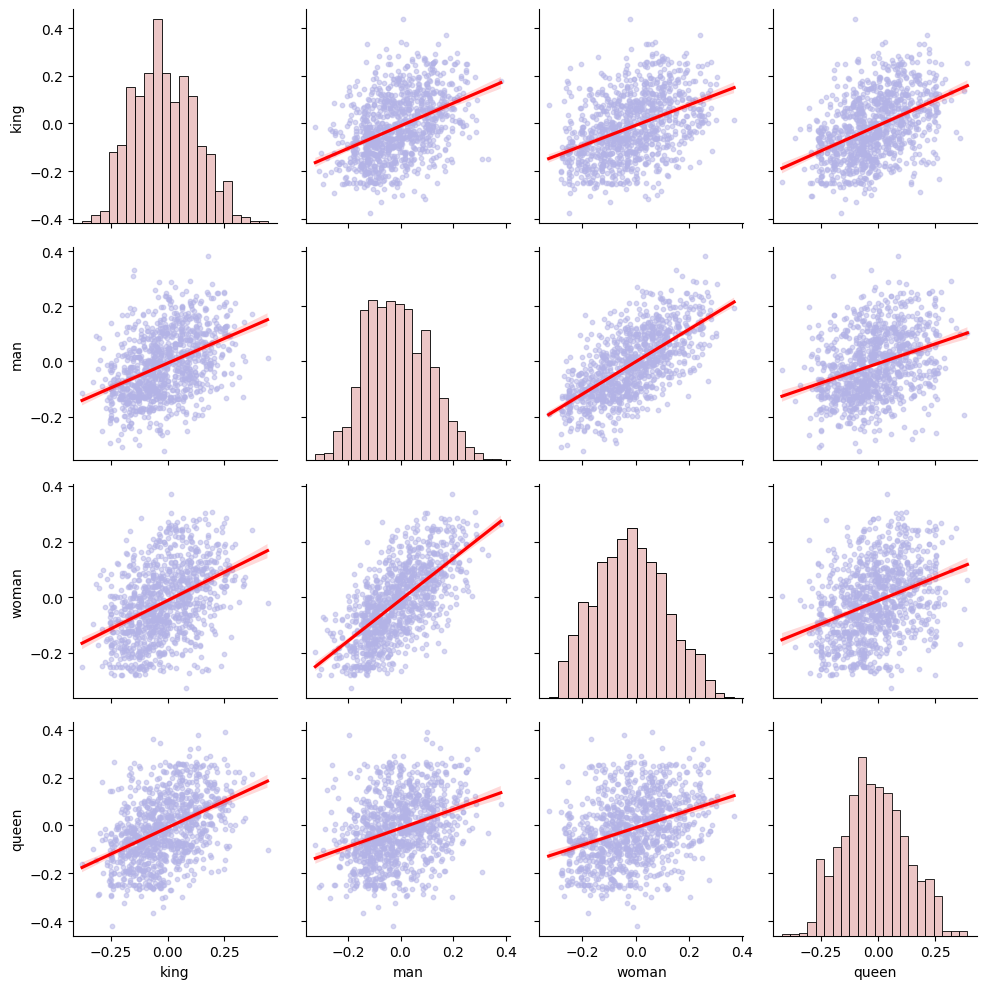

In [18]:
# visualize
sns.pairplot(df,kind='reg',
             plot_kws={'line_kws':{'color':'r'},
                       'scatter_kws':{'color':[.7,.7,.9],'s':10,'alpha':.5}},
             diag_kws={'color':[.9,.7,.7]}
            )

plt.tight_layout()
plt.show()